# ЛР №2. Виртуальные сенсоры и IoT-телеметрия

Основа: `robotics-course/05-perception/class.ipynb`.

Физический ESP32/MQTT-broker не требуется: IoT-поток моделируется локально как последовательность сообщений.

**Студент:** Кислов Илья Алексеевич **Группа:** ИНДОР-221 **Вариант:** 7

## Критерии оценки (20 баллов)

| Часть | Содержание | Баллы |
|---|---|---:|
| 1 | Модель физического процесса и виртуальные датчики | 5 |
| 2 | Телеметрия в формате сообщений и модель канала | 5 |
| 3 | Метрики качества телеметрии (обязательный минимум) | 2 |
| 4 | Графики: исходный и принятый ряды, ошибка, актуальность | 3 |
| 5 | Исследование влияния потерь и частоты, вывод | 3 |
| 6 | Методическое задание: фрагмент урока или игра для школьников | 2 |

## Смысл работы для будущего учителя

Любой школьный проект с датчиками устроен одинаково: **датчик измеряет → данные передаются →
человек видит результат на экране**. Датчик шумит и смещается, канал теряет и задерживает
сообщения, экран показывает последнее пришедшее значение. Работа учит измерять, сколько
теряется на каждом звене, и отвечает на вопрос: **как часто устройству отправлять данные?**

Три главных вывода, которые вы проверите на своих числах:

1. **Шум частотой не лечится** — погрешность прибора не уменьшается, если опрашивать его чаще.
2. **Потери бьют по свежести, а не по точности** — пропущенное сообщение делает данные на
   экране устаревшими.
3. **«Чаще» — не всегда «лучше»** — после точки насыщения рост частоты только расходует канал
   и батарейку.

В части 6 вы превратите один из этих выводов во фрагмент урока или игру для школьников.

In [1]:
VARIANT = 7
assert 1 <= VARIANT <= 25

In [2]:
from pathlib import Path
import subprocess, sys
repo=Path("robotics-course")
if not repo.exists():
    subprocess.run(["git","clone","--depth","1","--branch","2026",
                    "https://github.com/BosenkoTM/robotics-course.git",str(repo)],check=True)
perception=repo/"05-perception"
sys.path.insert(0,str(perception.resolve()))

In [3]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt

In [4]:
def variant_params(n):
    sensors=["Encoder","IMU","Encoder+IMU","LiDAR","Encoder+LiDAR"]
    freqs=[5,10,20,25,50]
    losses=[0,2,5,8,10]
    return {
        "sensor": sensors[(n-1)%5],
        "freq_hz": freqs[(n-1)//5],
        "noise_pct": [0.5,1.0,1.5,2.0,2.5][(n-1)%5],
        "loss_pct": losses[(n-1)//5],
        "seed": 200+n
    }
cfg=variant_params(VARIANT)
cfg

{'sensor': 'IMU', 'freq_hz': 10, 'noise_pct': 1.0, 'loss_pct': 2, 'seed': 207}

## Задание

Используя примеры моделей из `05-perception`, сформируйте виртуальные измерения.
Каждое измерение преобразуйте в сообщение:

```json
{"device_id":"robot01","seq":1,"timestamp":0.1,"sensor":"imu","value":0.02}
```

Далее смоделируйте потери сообщений и рассчитайте метрики качества канала.

## Часть 1. Модель процесса и виртуальные датчики (5 баллов)

Сгенерируйте не менее 30 с «истинного» процесса и снимите показания датчиков вашего варианта с заданной частотой, добавив шум (процент от полной шкалы датчика) и пропуски.

In [6]:
import math
from typing import List, Tuple

# ---------- параметры эксперимента (единые для всех вариантов) ----------
DEVICE_ID  = "robot01"
SIM_TIME   = 40.0        # длительность эксперимента, с (требуется не менее 30)
DT_TRUTH   = 0.001       # шаг «физической» модели, с (1 кГц)
WHEEL_R    = 0.05        # радиус колеса, м
WHEEL_BASE = 0.20        # колея, м

SCALE = {"encoder": 1.00, "imu": 2.00, "lidar": 5.00}
UNITS = {"encoder": "м/с", "imu": "рад/с", "lidar": "м"}

ENCODER_CPR   = 1024     # импульсов на оборот вала
ENCODER_QUAD  = 4        # квадратурное декодирование x4
IMU_BIAS0     = 0.010    # начальное смещение нуля гироскопа, рад/с
IMU_BIAS_WALK = 0.002    # случайное блуждание смещения, рад/с за секунду
LIDAR_RANGE   = SCALE["lidar"]
LIDAR_DROPOUT = 0.01     # доля недостоверных измерений дальномера

rng = np.random.default_rng(cfg["seed"])   # единственный источник случайности

# ---------- кинематическая модель DiffDrive из robotics-course ----------
import importlib.util
REPO_OK, DiffDrive = False, None
for _try in ("kinematic_models", "lib.kinematic_models"):
    try:
        DiffDrive = importlib.import_module(_try).DiffDrive
        REPO_OK = True
        break
    except Exception:
        pass
if DiffDrive is None:
    _km = repo / "04-mobile-robots" / "lib" / "kinematic_models.py"
    if _km.exists():
        try:
            _spec = importlib.util.spec_from_file_location("kinematic_models", _km)
            _mod = importlib.util.module_from_spec(_spec)
            sys.modules["kinematic_models"] = _mod
            _spec.loader.exec_module(_mod)
            DiffDrive, REPO_OK = _mod.DiffDrive, True
        except Exception as err:
            print("DiffDrive не загружен:", type(err).__name__, err)
print("DiffDrive из репозитория:", "да" if REPO_OK else "нет — используется встроенная модель")
print(f"Эксперимент: {SIM_TIME} с, шаг истины {DT_TRUTH*1000:.0f} мс, "
      f"частота {cfg['freq_hz']} Гц, seed {cfg['seed']}")


# ==================== 1.1. Истинный процесс и траектория ====================
def control_profile(t: float) -> Tuple[float, float]:
    """Программа движения робота: (линейная скорость, угловая скорость) в момент t."""
    if t < 8.0:
        return 0.60, 0.00                    # разгон и прямолинейный участок
    if t < 14.0:
        return 0.45, 0.55                    # поворот влево
    if t < 22.0:
        return 0.70, 0.00                    # быстрый прямой участок
    if t < 28.0:
        return 0.40, -0.70                   # поворот вправо
    if t < 34.0:
        return 0.55, 0.25 * math.sin(0.9 * t)  # плавная змейка
    return 0.20, 0.00                        # торможение перед остановкой


def diff_drive_forward(pose: np.ndarray, v: float, omega: float, dt: float) -> np.ndarray:
    """Шаг кинематики дифференциального привода (метод Эйлера)."""
    x, y, th = pose
    return np.array([x + v * math.cos(th) * dt,
                     y + v * math.sin(th) * dt,
                     th + omega * dt])


robot = DiffDrive(wheel_radius=WHEEL_R, wheel_base=WHEEL_BASE) if REPO_OK else None
step = (lambda p, v, w, dt: robot.forward(p, v, w, dt)) if REPO_OK else diff_drive_forward

n_truth = int(SIM_TIME / DT_TRUTH) + 1
pose = np.array([0.5, 0.5, 0.0])
rows = []
for k in range(n_truth):
    t = k * DT_TRUTH
    v, omega = control_profile(t)
    rows.append({"t": t, "x": pose[0], "y": pose[1], "theta": pose[2],
                 "v": v, "omega": omega,
                 "w_right": (v + omega * WHEEL_BASE / 2) / WHEEL_R,
                 "w_left":  (v - omega * WHEEL_BASE / 2) / WHEEL_R})
    pose = step(pose, v, omega, DT_TRUTH)

truth = pd.DataFrame(rows)

print(f"Эталонная траектория: {len(truth)} точек с шагом {DT_TRUTH * 1000:.0f} мс")
print(f"Пройденный путь     : {float(truth['v'].sum() * DT_TRUTH):.2f} м")
print(f"Диапазон v          : {truth['v'].min():.2f} … {truth['v'].max():.2f} м/с")
print(f"Диапазон omega      : {truth['omega'].min():.2f} … {truth['omega'].max():.2f} рад/с")
truth.head(3)


# ================= 1.2. Модели виртуальных датчиков =================
OBSTACLES = [(4.0, 3.0, 0.60), (7.5, 6.0, 0.80), (2.0, 6.5, 0.50)]


def ray_distance(pose: np.ndarray, obstacles: list, max_range: float) -> float:
    """Дальность по лучу вдоль курса робота до ближайшего препятствия."""
    ox, oy, th = pose
    dx, dy = math.cos(th), math.sin(th)
    best = max_range
    for cx, cy, r in obstacles:
        fx, fy = ox - cx, oy - cy
        b = 2.0 * (fx * dx + fy * dy)
        c = fx * fx + fy * fy - r * r
        disc = b * b - 4.0 * c
        if disc < 0.0:
            continue
        sq = math.sqrt(disc)
        for t in ((-b - sq) / 2.0, (-b + sq) / 2.0):
            if 0.0 <= t < best:
                best = t
    return float(best)


def encoder_truth(row: pd.Series) -> float:
    """Истинная линейная скорость, восстановленная по угловым скоростям колёс, м/с."""
    return WHEEL_R * (row["w_right"] + row["w_left"]) / 2.0


def encoder_measure(value: float, sigma: float, generator: np.random.Generator) -> float:
    """Модель энкодера: шум + квантование по разрешению датчика."""
    resolution = 2 * math.pi * WHEEL_R / (ENCODER_CPR * ENCODER_QUAD)   # м на импульс
    noisy = value + generator.normal(0.0, sigma)
    return float(round(noisy / resolution) * resolution)                # квантование


class ImuModel:
    """Гироскоп: белый шум измерения плюс дрейф нуля (случайное блуждание)."""

    def __init__(self, sigma: float, generator: np.random.Generator):
        self.sigma = sigma
        self.rng = generator
        self.bias = IMU_BIAS0

    def measure(self, value: float, dt: float) -> float:
        self.bias += self.rng.normal(0.0, IMU_BIAS_WALK * math.sqrt(max(dt, 1e-9)))
        return float(value + self.bias + self.rng.normal(0.0, self.sigma))


def lidar_measure(value: float, sigma: float, generator: np.random.Generator) -> float:
    """Дальномер: шум измерения и редкие недостоверные отсчёты (dropout)."""
    if generator.random() < LIDAR_DROPOUT:
        return float("nan")
    return float(np.clip(value + generator.normal(0.0, sigma), 0.0, LIDAR_RANGE))


def sensors_of(variant_sensor: str) -> List[str]:
    """Список потоков телеметрии по названию сенсора варианта."""
    return [s.strip().lower() for s in variant_sensor.split("+")]


STREAMS = sensors_of(cfg["sensor"])
SIGMA = {s: cfg["noise_pct"] / 100.0 * SCALE[s] for s in STREAMS}

print("Потоки телеметрии варианта:", STREAMS)
for s in STREAMS:
    print(f"  {s:<8} полная шкала {SCALE[s]} {UNITS[s]:<6} "
          f"-> сигма шума {SIGMA[s]:.4f} {UNITS[s]}")
print(f"\nРазрешение энкодера: "
      f"{2 * math.pi * WHEEL_R / (ENCODER_CPR * ENCODER_QUAD) * 1000:.4f} мм на импульс")
_p = np.array([0.5, 0.5, 0.0])
print(f"Проверка дальномера: в пустом поле {ray_distance(_p, [], LIDAR_RANGE):.2f} м, "
      f"на препятствие в 2 м {ray_distance(np.array([2.0, 3.0, 0.0]), [(4.0, 3.0, 0.6)], LIDAR_RANGE):.2f} м")


# ================ 1.3. Съём показаний с частотой варианта ================
def sample_measurements(truth: pd.DataFrame, variant_cfg: dict,
                        generator: np.random.Generator) -> pd.DataFrame:
    """Снять показания датчиков с частотой варианта.

    Args:
        truth: эталонная траектория с шагом ``DT_TRUTH``.
        variant_cfg: конфигурация варианта (``sensor``, ``freq_hz``, ``noise_pct``).
        generator: генератор случайных чисел (задаёт воспроизводимость).

    Returns:
        DataFrame с колонками ``t``, ``sensor``, ``truth``, ``measured``, ``unit``.
    """
    streams = sensors_of(variant_cfg["sensor"])
    sigma = {s: variant_cfg["noise_pct"] / 100.0 * SCALE[s] for s in streams}
    period = 1.0 / variant_cfg["freq_hz"]
    times = np.arange(0.0, SIM_TIME, period)
    index = (times / DT_TRUTH).astype(int)
    imu = ImuModel(sigma.get("imu", 0.0), generator)

    records: List[dict] = []
    for t, idx in zip(times, index):
        row = truth.iloc[idx]
        pose = np.array([row["x"], row["y"], row["theta"]])
        for stream in streams:
            if stream == "encoder":
                true_value = encoder_truth(row)
                measured = encoder_measure(true_value, sigma["encoder"], generator)
            elif stream == "imu":
                true_value = float(row["omega"])
                measured = imu.measure(true_value, period)
            else:
                true_value = ray_distance(pose, OBSTACLES, LIDAR_RANGE)
                measured = lidar_measure(true_value, sigma["lidar"], generator)
            records.append({"t": float(t), "sensor": stream,
                            "truth": float(true_value), "measured": measured,
                            "unit": UNITS[stream]})
    return pd.DataFrame(records)


meas = sample_measurements(truth, cfg, rng)

print(f"Снято отсчётов: {len(meas)} "
      f"({len(STREAMS)} поток(а) x {len(meas) // len(STREAMS)} отсчётов)")
print(f"Недостоверных измерений (NaN): {int(meas['measured'].isna().sum())}\n")
summary = (meas.dropna(subset=["measured"])
           .assign(err=lambda d: d["measured"] - d["truth"])
           .groupby("sensor")
           .agg(n=("err", "size"), bias=("err", "mean"),
                rmse=("err", lambda e: float(np.sqrt(np.mean(e ** 2)))),
                max_abs=("err", lambda e: float(np.max(np.abs(e)))))
           .round(5))
print(summary.to_string())
meas.head(4)

DiffDrive из репозитория: да
Эксперимент: 40.0 с, шаг истины 1 мс, частота 10 Гц, seed 207
Эталонная траектория: 40001 точек с шагом 1 мс
Пройденный путь     : 20.00 м
Диапазон v          : 0.20 … 0.70 м/с
Диапазон omega      : -0.70 … 0.55 рад/с
Потоки телеметрии варианта: ['imu']
  imu      полная шкала 2.0 рад/с  -> сигма шума 0.0200 рад/с

Разрешение энкодера: 0.0767 мм на импульс
Проверка дальномера: в пустом поле 5.00 м, на препятствие в 2 м 1.40 м
Снято отсчётов: 400 (1 поток(а) x 400 отсчётов)
Недостоверных измерений (NaN): 0

          n     bias     rmse  max_abs
sensor                                
imu     400  0.01089  0.02341  0.09005


,t,sensor,truth,measured,unit
0,0.0,imu,0.0,-0.021106,рад/с
1,0.1,imu,0.0,-0.006189,рад/с
2,0.2,imu,0.0,0.024554,рад/с
3,0.3,imu,0.0,0.024466,рад/с


In [5]:
def sample_measurements(truth: pd.DataFrame, variant_cfg: dict,
                        generator: np.random.Generator) -> pd.DataFrame:
    """Снять показания датчиков с частотой варианта.

    Args:
        truth: эталонная траектория с шагом ``DT_TRUTH``.
        variant_cfg: конфигурация варианта (``sensor``, ``freq_hz``, ``noise_pct``).
        generator: генератор случайных чисел (задаёт воспроизводимость).

    Returns:
        DataFrame с колонками ``t``, ``sensor``, ``truth``, ``measured``, ``unit``.
    """
    streams = sensors_of(variant_cfg["sensor"])
    sigma = {s: variant_cfg["noise_pct"] / 100.0 * SCALE[s] for s in streams}
    period = 1.0 / variant_cfg["freq_hz"]
    times = np.arange(0.0, SIM_TIME, period)
    index = (times / DT_TRUTH).astype(int)
    imu = ImuModel(sigma.get("imu", 0.0), generator)

    records: List[dict] = []
    for t, idx in zip(times, index):
        row = truth.iloc[idx]
        pose = np.array([row["x"], row["y"], row["theta"]])
        for stream in streams:
            if stream == "encoder":
                true_value = encoder_truth(row)
                measured = encoder_measure(true_value, sigma["encoder"], generator)
            elif stream == "imu":
                true_value = float(row["omega"])
                measured = imu.measure(true_value, period)
            else:
                true_value = ray_distance(pose, OBSTACLES, LIDAR_RANGE)
                measured = lidar_measure(true_value, sigma["lidar"], generator)
            records.append({"t": float(t), "sensor": stream,
                            "truth": float(true_value), "measured": measured,
                            "unit": UNITS[stream]})
    return pd.DataFrame(records)


meas = sample_measurements(truth, cfg, rng)

print(f"Снято отсчётов: {len(meas)} "
      f"({len(STREAMS)} поток(а) x {len(meas) // len(STREAMS)} отсчётов)")
print(f"Недостоверных измерений (NaN): {int(meas['measured'].isna().sum())}\n")
summary = (meas.dropna(subset=["measured"])
           .assign(err=lambda d: d["measured"] - d["truth"])
           .groupby("sensor")
           .agg(n=("err", "size"), bias=("err", "mean"),
                rmse=("err", lambda e: float(np.sqrt(np.mean(e ** 2)))),
                max_abs=("err", lambda e: float(np.max(np.abs(e)))))
           .round(5))
print(summary.to_string())
meas.head(4)

NameError: name 'truth' is not defined

## Часть 2. Телеметрия и модель канала (5 баллов)

Преобразуйте измерения в сообщения `device_id / seq / timestamp / sensor / value` и смоделируйте публикацию и приём: потери по варианту, задержку доставки.

In [7]:
import json
from dataclasses import dataclass

# ==================== 2.1. Сообщения телеметрии ====================
def build_messages(meas: pd.DataFrame, device_id: str = DEVICE_ID) -> List[dict]:
    """Преобразовать измерения в сообщения телеметрии.

    Формат сообщения соответствует заданию:
    ``{"device_id", "seq", "timestamp", "sensor", "value"}``.
    """
    messages: List[dict] = []
    for seq, row in enumerate(meas.sort_values("t").itertuples(index=False), start=1):
        value = None if (isinstance(row.measured, float) and math.isnan(row.measured)) \
            else round(float(row.measured), 6)
        messages.append({"device_id": device_id,
                         "seq": seq,
                         "timestamp": round(float(row.t), 4),
                         "sensor": row.sensor,
                         "value": value})
    return messages


messages = build_messages(meas)
payload_bytes = [len(json.dumps(m, ensure_ascii=False).encode("utf-8")) for m in messages]

print("Пример сообщения:")
print(json.dumps(messages[0], ensure_ascii=False))
print(json.dumps(messages[1], ensure_ascii=False))
print(f"\nВсего сообщений        : {len(messages)}")
print(f"Средний размер payload : {np.mean(payload_bytes):.1f} байт")
print(f"Полезная нагрузка канала: {np.mean(payload_bytes) * len(messages) / SIM_TIME:.0f} байт/с "
      f"({np.mean(payload_bytes) * len(messages) / SIM_TIME * 8 / 1000:.2f} кбит/с)")


# ============ 2.2. Модель канала: публикация и приём ============
@dataclass
class ChannelConfig:
    """Параметры виртуального канала связи."""
    loss_pct: float = 0.0        # вероятность потери отдельного сообщения, %
    base_delay_s: float = 0.005  # базовая задержка доставки, с
    jitter_s: float = 0.004      # разброс задержки (экспоненциальный хвост), с
    burst_len: int = 1           # средняя длина серии потерь (1 = потери независимы)


def transmit(messages: List[dict], channel: ChannelConfig,
             generator: np.random.Generator) -> pd.DataFrame:
    """Промоделировать публикацию и приём сообщений.

    Сообщение теряется с вероятностью ``loss_pct``; при ``burst_len > 1`` потери
    группируются в серии. Каждому доставленному сообщению приписывается время приёма
    с задержкой и джиттером. Приёмник сортирует сообщения по времени прибытия.

    Returns:
        DataFrame принятых сообщений с колонками
        ``seq, sensor, timestamp, value, t_rx, delay``.
    """
    p_loss = channel.loss_pct / 100.0
    received: List[dict] = []
    burst_left = 0

    for message in messages:
        if burst_left > 0:                       # продолжается серия потерь
            burst_left -= 1
            continue
        if generator.random() < p_loss:
            burst_left = max(0, channel.burst_len - 1)
            continue
        delay = channel.base_delay_s + generator.exponential(channel.jitter_s)
        received.append({**message, "t_rx": message["timestamp"] + delay,
                         "delay": delay})

    frame = pd.DataFrame(received)
    return frame.sort_values("t_rx").reset_index(drop=True) if len(frame) else frame


channel = ChannelConfig(loss_pct=cfg["loss_pct"])
rx = transmit(messages, channel, rng)

lost_seq = sorted(set(m["seq"] for m in messages) - set(rx["seq"]))
print(f"Отправлено : {len(messages)}")
print(f"Принято    : {len(rx)}")
print(f"Потеряно   : {len(lost_seq)} "
      f"({100 * len(lost_seq) / len(messages):.2f} %, "
      f"задано в варианте {cfg['loss_pct']} %)")
print(f"Задержка   : медиана {rx['delay'].median() * 1000:.1f} мс, "
      f"максимум {rx['delay'].max() * 1000:.1f} мс")
print(f"Первые потерянные seq: {lost_seq[:10]}")
rx.head(3)

Пример сообщения:
{"device_id": "robot01", "seq": 1, "timestamp": 0.0, "sensor": "imu", "value": -0.021106}
{"device_id": "robot01", "seq": 2, "timestamp": 0.1, "sensor": "imu", "value": -0.006189}

Всего сообщений        : 400
Средний размер payload : 90.7 байт
Полезная нагрузка канала: 907 байт/с (7.26 кбит/с)
Отправлено : 400
Принято    : 393
Потеряно   : 7 (1.75 %, задано в варианте 2 %)
Задержка   : медиана 7.8 мс, максимум 23.0 мс
Первые потерянные seq: [26, 67, 107, 130, 133, 151, 280]


,device_id,seq,timestamp,sensor,value,t_rx,delay
0,robot01,1,0.0,imu,-0.021106,0.006940,0.006940
1,robot01,2,0.1,imu,-0.006189,0.108633,0.008633
2,robot01,3,0.2,imu,0.024554,0.209115,0.009115


## Часть 3. Метрики качества (2 балла)

Обязательный минимум — по 0,5 балла за каждую метрику:

| Метрика | Что показывает |
|---|---|
| фактическая частота приёма, Гц | сколько сообщений в секунду реально дошло |
| фактическая доля потерь, % | сравнить с заданной; объяснить расхождение |
| ошибка датчика (RMSE измерения) | насколько точен сам прибор |
| ошибка у потребителя (RMSE восстановленного сигнала) | насколько точно то, что видно на экране |

Серии потерь, задержка, разрывы и возраст данных — по желанию (расширенный уровень).

In [8]:
# ========== Часть 3. Метрики качества телеметрии ==========
def zoh_reconstruct(rx_stream: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """Восстановить сигнал на равномерной сетке экстраполяцией «нуль-порядка».

    Потребитель телеметрии видит только принятые сообщения и до прихода следующего
    держит последнее известное значение (zero-order hold).
    """
    values = rx_stream["value"].to_numpy(dtype=float)
    stamps = rx_stream["timestamp"].to_numpy(dtype=float)
    valid = ~np.isnan(values)
    values, stamps = values[valid], stamps[valid]
    if len(stamps) == 0:
        return np.full_like(grid, np.nan, dtype=float)
    idx = np.searchsorted(stamps, grid, side="right") - 1
    return np.where(idx >= 0, values[np.clip(idx, 0, None)], np.nan)


def age_of_information(rx_stream: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """Возраст информации: время с момента формирования последнего принятого пакета."""
    stamps = np.sort(rx_stream["timestamp"].to_numpy(dtype=float))
    if len(stamps) == 0:
        return np.full_like(grid, np.nan, dtype=float)
    idx = np.searchsorted(stamps, grid, side="right") - 1
    return np.where(idx >= 0, grid - stamps[np.clip(idx, 0, None)], np.nan)


def channel_metrics(messages: List[dict], rx: pd.DataFrame, meas: pd.DataFrame,
                    variant_cfg: dict) -> dict:
    """Метрики качества виртуального IoT-канала и восстановления сигнала."""
    streams = sensors_of(variant_cfg["sensor"])
    n_sent = len(messages)
    seq_sent = np.array([m["seq"] for m in messages])
    seq_rx = np.sort(rx["seq"].to_numpy()) if len(rx) else np.array([], dtype=int)
    lost = np.setdiff1d(seq_sent, seq_rx)
    gaps = np.diff(seq_rx)

    result = {
        "messages_sent":      n_sent,
        "messages_received":  len(rx),
        "loss_pct_actual":    round(100.0 * len(lost) / n_sent, 3),
        "pdr_pct":            round(100.0 * len(rx) / n_sent, 3),
        "rate_nominal_hz":    variant_cfg["freq_hz"] * len(streams),
        "rate_actual_hz":     round(len(rx) / SIM_TIME, 3),
        "longest_loss_burst": int(gaps.max() - 1) if len(gaps) else 0,
        "delay_median_ms":    round(float(rx["delay"].median()) * 1000, 2) if len(rx) else None,
        "jitter_ms":          round(float(rx["delay"].std()) * 1000, 2) if len(rx) else None,
    }

    grid = np.arange(0.0, SIM_TIME, 0.01)
    for stream in streams:
        src = meas[meas["sensor"] == stream].sort_values("t")
        err = (src["measured"] - src["truth"]).dropna().to_numpy()
        truth_grid = np.interp(grid, src["t"], src["truth"])

        rx_s = rx[rx["sensor"] == stream].sort_values("timestamp") if len(rx) else rx
        recon = zoh_reconstruct(rx_s, grid) if len(rx_s) else np.full(len(grid), np.nan)
        ok = ~np.isnan(recon)
        stamps = rx_s["timestamp"].to_numpy() if len(rx_s) else np.array([])
        gap_s = np.diff(np.r_[0.0, stamps, SIM_TIME])
        aoi = age_of_information(rx_s, grid) if len(rx_s) else np.full(len(grid), np.nan)

        result[f"{stream}_sensor_rmse"] = round(float(np.sqrt(np.mean(err ** 2))), 5)
        result[f"{stream}_sensor_bias"] = round(float(np.mean(err)), 5)
        result[f"{stream}_recon_rmse"] = round(float(np.sqrt(np.mean(
            (recon[ok] - truth_grid[ok]) ** 2))), 5) if ok.any() else None
        result[f"{stream}_max_gap_s"] = round(float(gap_s.max()), 3)
        result[f"{stream}_aoi_mean_s"] = round(float(np.nanmean(aoi)), 4)
        result[f"{stream}_aoi_max_s"] = round(float(np.nanmax(aoi)), 4)
    return result


metrics = channel_metrics(messages, rx, meas, cfg)
print(pd.Series(metrics, dtype=object).to_string())

messages_sent             400
messages_received         393
loss_pct_actual          1.75
pdr_pct                 98.25
rate_nominal_hz            10
rate_actual_hz          9.825
longest_loss_burst          1
delay_median_ms          7.83
jitter_ms                 3.9
imu_sensor_rmse       0.02341
imu_sensor_bias       0.01089
imu_recon_rmse        0.04091
imu_max_gap_s             0.2
imu_aoi_mean_s         0.0468
imu_aoi_max_s            0.19


## Часть 4. Графики (3 балла)

Истинный, измеренный и принятый ряды; ошибка датчика; при желании — интервалы прибытия и возраст данных. Подпишите оси и единицы измерения.

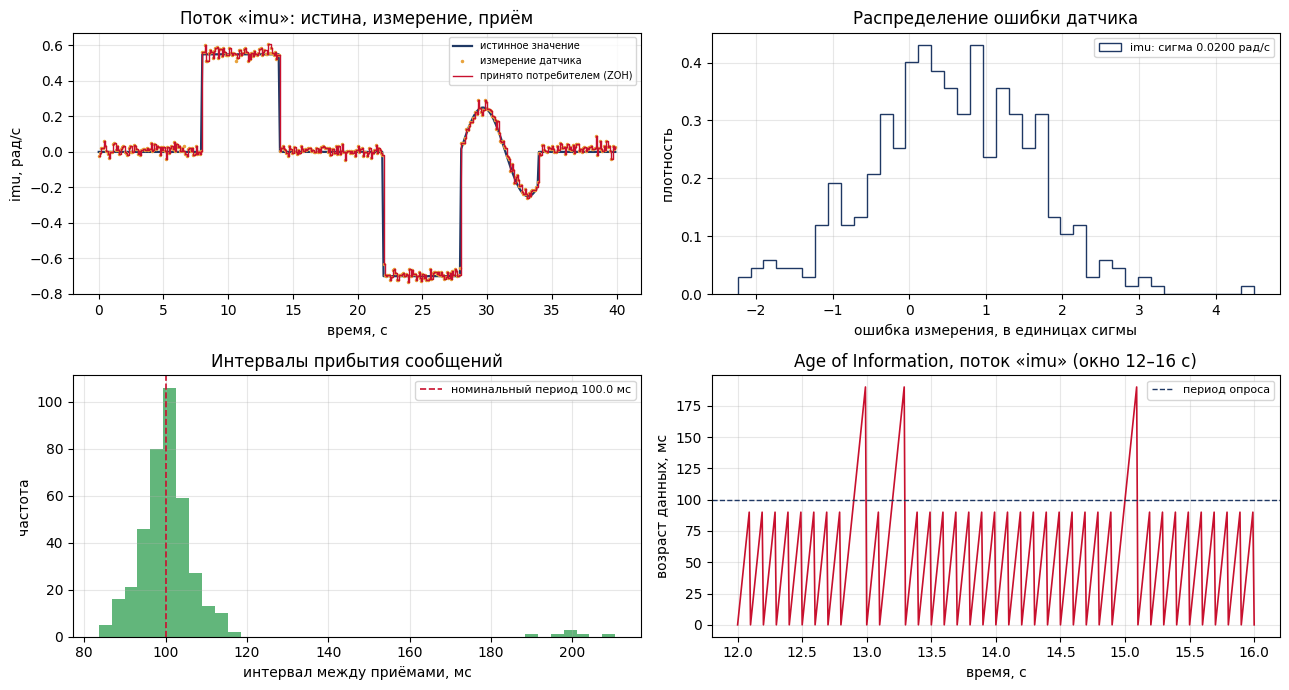

поток        AoI упрощённый, мс     AoI по определению, мс
imu           46.8 / 190.0             60.9 / 216.5    

формат: средний / максимальный; теоретический минимум среднего без потерь = половина периода + средняя задержка ≈ 50 + 9.1 мс


In [9]:
# ==================== Часть 4. Графики ====================
grid = np.arange(0.0, SIM_TIME, 0.01)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

# --- 1. исходный, измеренный и принятый ряды по первому потоку
stream = STREAMS[0]
src = meas[meas["sensor"] == stream]
rx_s = rx[rx["sensor"] == stream].sort_values("timestamp")
ax = axes[0, 0]
ax.plot(src["t"], src["truth"], lw=1.6, color="#1F3864", label="истинное значение", zorder=2)
ax.plot(src["t"], src["measured"], ".", ms=3, color="#E8A33D",
        label="измерение датчика", zorder=3)
ax.step(rx_s["timestamp"], rx_s["value"], where="post", lw=1.0, color="#C8102E",
        label="принято потребителем (ZOH)", zorder=4)
ax.set_xlabel("время, с"); ax.set_ylabel(f"{stream}, {UNITS[stream]}")
ax.set_title(f"Поток «{stream}»: истина, измерение, приём")
ax.grid(alpha=.3); ax.legend(fontsize=7)

# --- 2. ошибка измерения
ax = axes[0, 1]
for s, color in zip(STREAMS, ["#1F3864", "#E8A33D", "#2E9E4F"]):
    d = meas[meas["sensor"] == s].dropna(subset=["measured"])
    err = (d["measured"] - d["truth"]) / SIGMA[s]
    ax.hist(err, bins=40, histtype="step", lw=1.6, density=True, color=color,
            label=f"{s}: сигма {SIGMA[s]:.4f} {UNITS[s]}")
ax.set_xlabel("ошибка измерения, в единицах сигмы"); ax.set_ylabel("плотность")
ax.set_title("Распределение ошибки датчика")
ax.grid(alpha=.3); ax.legend(fontsize=8)

# --- 3. интервалы между принятыми сообщениями
ax = axes[1, 0]
inter = np.diff(rx["t_rx"].to_numpy()) * 1000
ax.hist(inter, bins=40, color="#2E9E4F", alpha=.75)
nominal = 1000.0 / (cfg["freq_hz"] * len(STREAMS))
ax.axvline(nominal, color="#C8102E", ls="--", lw=1.2,
           label=f"номинальный период {nominal:.1f} мс")
ax.set_xlabel("интервал между приёмами, мс"); ax.set_ylabel("частота")
ax.set_title("Интервалы прибытия сообщений")
ax.grid(alpha=.3); ax.legend(fontsize=8)

# --- 4. возраст информации
ax = axes[1, 1]
window = (grid >= 12.0) & (grid <= 16.0)          # окно 4 с: иначе пила не читается
aoi = age_of_information(rx_s, grid)
ax.plot(grid[window], aoi[window] * 1000, lw=1.2, color="#C8102E")
ax.axhline(1000.0 / cfg["freq_hz"], color="#1F3864", ls="--", lw=1.0,
           label="период опроса")
ax.set_xlabel("время, с"); ax.set_ylabel("возраст данных, мс")
ax.set_title(f"Age of Information, поток «{stream}» (окно 12–16 с)")
ax.grid(alpha=.3); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()


# ============ 4.1. Возраст информации по определению ============
# ============================================================================
#  Дополнительная ячейка: возраст информации по определению
#  AoI(t) = t − u(t), где u(t) — время ИЗМЕРЕНИЯ самого свежего сообщения,
#  которое к моменту t уже ПРИШЛО потребителю. Функция age_of_information выше
#  упрощает: считает сообщение доступным в момент измерения (без задержки
#  доставки) и оценивает возраст на сетке 10 мс. Здесь — точная версия.
# ============================================================================
def aoi_delivered(rx_stream: pd.DataFrame, step: float = 0.0005) -> Tuple[float, float]:
    """Средний и максимальный AoI с учётом времени приёма, сетка 0,5 мс."""
    t_grid = np.arange(0.0, SIM_TIME, step)
    order = np.argsort(rx_stream["t_rx"].to_numpy())
    arrived = rx_stream["t_rx"].to_numpy()[order]
    # самое свежее измерение среди пришедших (с учётом переупорядочивания)
    freshest = np.maximum.accumulate(rx_stream["timestamp"].to_numpy()[order])
    idx = np.searchsorted(arrived, t_grid, side="right") - 1
    age = np.where(idx >= 0, t_grid - freshest[np.clip(idx, 0, None)], np.nan)
    return float(np.nanmean(age)), float(np.nanmax(age))


print(f"{'поток':<8} {'AoI упрощённый, мс':>22} {'AoI по определению, мс':>26}")
for _s in STREAMS:
    _rx_s = rx[rx["sensor"] == _s]
    _mean, _max = aoi_delivered(_rx_s)
    print(f"{_s:<8} {metrics[f'{_s}_aoi_mean_s'] * 1000:>9.1f} / {metrics[f'{_s}_aoi_max_s'] * 1000:<9.1f}"
          f" {_mean * 1000:>12.1f} / {_max * 1000:<9.1f}")
print("\nформат: средний / максимальный; теоретический минимум среднего без потерь "
      f"= половина периода + средняя задержка ≈ {500 / cfg['freq_hz']:.0f} + "
      f"{rx['delay'].mean() * 1000:.1f} мс")

## Часть 5. Исследование (3 балла)

Измените по одному параметру (доля потерь, частота публикации), остальные оставьте как в варианте. Постройте таблицу и график зависимости метрик от параметра.

Влияние потерь пакетов (частота 10 Гц, поток «imu»)

 loss_pct  messages_received  loss_pct_actual  rate_actual_hz  longest_loss_burst  imu_recon_rmse  imu_max_gap_s  imu_aoi_mean_s  imu_aoi_max_s
        0                400             0.00          10.000                   0         0.04020            0.1          0.0450           0.09
        2                393             1.75           9.825                   1         0.04091            0.2          0.0468           0.19
        5                378             5.50           9.450                   2         0.04016            0.3          0.0508           0.29
       10                363             9.25           9.075                   2         0.04019            0.3          0.0545           0.29
       20                320            20.00           8.000                   3         0.04892            0.4          0.0700           0.39
       30                287            28.25           7.175                   4  

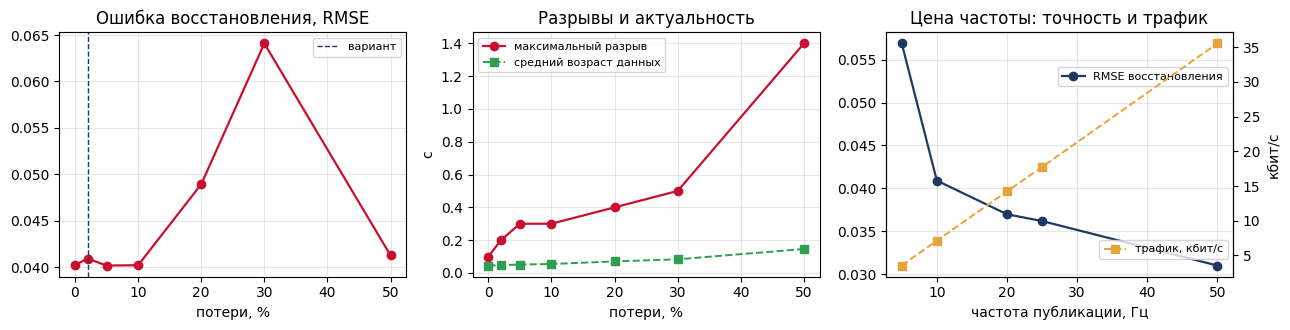

In [10]:
# ---------- 5.0. Функция одного прогона + влияние потерь ----------
def run_pipeline(variant_cfg: dict, loss_pct: float = None,
                 freq_hz: float = None) -> dict:
    """Полный прогон конвейера «датчик -> сообщения -> канал -> метрики».

    Меняется ровно один параметр, остальные берутся из конфигурации варианта:
    это однофакторный эксперимент.
    """
    local = dict(variant_cfg)
    if loss_pct is not None:
        local["loss_pct"] = loss_pct
    if freq_hz is not None:
        local["freq_hz"] = freq_hz

    generator = np.random.default_rng(local["seed"])
    local_meas = sample_measurements(truth, local, generator)
    local_messages = build_messages(local_meas)
    local_rx = transmit(local_messages, ChannelConfig(loss_pct=local["loss_pct"]), generator)
    result = channel_metrics(local_messages, local_rx, local_meas, local)
    return {"freq_hz": local["freq_hz"], "loss_pct": local["loss_pct"], **result}


first = STREAMS[0]
loss_sweep = pd.DataFrame([run_pipeline(cfg, loss_pct=p)
                           for p in [0, 2, 5, 10, 20, 30, 50]])[
    ["loss_pct", "messages_received", "loss_pct_actual", "rate_actual_hz",
     "longest_loss_burst", f"{first}_recon_rmse", f"{first}_max_gap_s",
     f"{first}_aoi_mean_s", f"{first}_aoi_max_s"]]

print(f"Влияние потерь пакетов (частота {cfg['freq_hz']} Гц, поток «{first}»)\n")
print(loss_sweep.to_string(index=False))

# ---------- 5.1а. То же на 30 зёрнах: один прогон — не доказательство ----------
# ============================================================================
#  Дополнительная ячейка: один прогон — не доказательство
#  Тот же однофакторный эксперимент, но на 30 разных зёрнах генератора.
#  Меняется только случайная реализация шума и потерь, параметры те же.
# ============================================================================
_rows = []
for _p in [0, 2, 5, 10, 20, 30, 50]:
    _runs = [run_pipeline(dict(cfg, seed=_s), loss_pct=_p) for _s in range(300, 330)]
    _rmse = np.array([r[f"{first}_recon_rmse"] for r in _runs])
    _rows.append({"loss_pct": _p,
                  "recon_rmse_mean": round(float(_rmse.mean()), 5),
                  "recon_rmse_sd": round(float(_rmse.std()), 5),
                  "max_gap_mean_s": round(float(np.mean([r[f"{first}_max_gap_s"] for r in _runs])), 3),
                  "aoi_mean_s": round(float(np.mean([r[f"{first}_aoi_mean_s"] for r in _runs])), 4)})
seed_sweep = pd.DataFrame(_rows)
print(f"Влияние потерь, среднее по 30 прогонам (поток «{first}»)\n")
print(seed_sweep.to_string(index=False))

# ---------- 5.1б. Гипотеза: опасны не потери, а их серии ----------
# ============================================================================
#  Дополнительная ячейка: проверка гипотезы «опасны не потери, а их серии»
#  Доля потерь одинакова (~5 %), различается только длина серии burst_len.
#  Вероятность начала серии подобрана так, чтобы общая доля потерь сохранилась.
# ============================================================================
_rows = []
for _bl in [1, 3, 5]:
    _p_start = 5.0 / (_bl - 0.05 * (_bl - 1))      # итоговая доля потерь ≈ 5 %
    _res = []
    for _s in range(300, 330):
        _gen = np.random.default_rng(_s)
        _cfg = dict(cfg, seed=_s)
        _meas = sample_measurements(truth, _cfg, _gen)
        _msgs = build_messages(_meas)
        _rx = transmit(_msgs, ChannelConfig(loss_pct=_p_start, burst_len=_bl), _gen)
        _res.append(channel_metrics(_msgs, _rx, _meas, _cfg))
    _rows.append({"burst_len": _bl,
                  "loss_actual_pct": round(float(np.mean([r["loss_pct_actual"] for r in _res])), 2),
                  f"{first}_recon_rmse": round(float(np.mean([r[f"{first}_recon_rmse"] for r in _res])), 5),
                  f"{first}_max_gap_s": round(float(np.mean([r[f"{first}_max_gap_s"] for r in _res])), 3),
                  f"{first}_aoi_max_s": round(float(np.mean([r[f"{first}_aoi_max_s"] for r in _res])), 3)})
burst_test = pd.DataFrame(_rows)
print("Одинаковая доля потерь, разная длина серий (среднее по 30 прогонам)\n")
print(burst_test.to_string(index=False))

# ---------- 5.2. Влияние частоты публикации ----------
freq_rows = [run_pipeline(cfg, freq_hz=f) for f in [5, 10, 20, 25, 50]]
freq_sweep = pd.DataFrame(freq_rows)[
    ["freq_hz", "messages_sent", "messages_received", "rate_actual_hz",
     f"{first}_sensor_rmse", f"{first}_recon_rmse",
     f"{first}_max_gap_s", f"{first}_aoi_mean_s"]]
freq_sweep["payload_bps"] = (freq_sweep["messages_received"] *
                             np.mean(payload_bytes) * 8 / SIM_TIME).round(0)

print(f"Влияние частоты публикации (потери {cfg['loss_pct']} %, поток «{first}»)\n")
print(freq_sweep.to_string(index=False))

# ---------- 5.3. Графики исследования ----------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

axes[0].plot(loss_sweep["loss_pct"], loss_sweep[f"{first}_recon_rmse"],
             "o-", color="#C8102E", lw=1.6)
axes[0].axvline(cfg["loss_pct"], color="#1F3864", ls="--", lw=1.0, label="вариант")
axes[0].set_xlabel("потери, %"); axes[0].set_title("Ошибка восстановления, RMSE")
axes[0].legend(fontsize=8)

axes[1].plot(loss_sweep["loss_pct"], loss_sweep[f"{first}_max_gap_s"],
             "o-", color="#C8102E", lw=1.6, label="максимальный разрыв")
axes[1].plot(loss_sweep["loss_pct"], loss_sweep[f"{first}_aoi_mean_s"],
             "s--", color="#2E9E4F", lw=1.4, label="средний возраст данных")
axes[1].set_xlabel("потери, %"); axes[1].set_ylabel("с")
axes[1].set_title("Разрывы и актуальность"); axes[1].legend(fontsize=8)

axes[2].plot(freq_sweep["freq_hz"], freq_sweep[f"{first}_recon_rmse"],
             "o-", color="#1F3864", lw=1.6, label="RMSE восстановления")
ax2 = axes[2].twinx()
ax2.plot(freq_sweep["freq_hz"], freq_sweep["payload_bps"] / 1000,
         "s--", color="#E8A33D", lw=1.4, label="трафик, кбит/с")
ax2.set_ylabel("кбит/с")
axes[2].set_xlabel("частота публикации, Гц")
axes[2].set_title("Цена частоты: точность и трафик")
axes[2].legend(fontsize=8, loc="upper right", bbox_to_anchor=(1.0, 0.88))
ax2.legend(fontsize=8, loc="lower right", bbox_to_anchor=(1.0, 0.05))

for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Вывод

Опишите влияние частоты, шума и потерь на качество телеметрии. Каждый пункт — со ссылкой на
**ваши** числа: заданная и фактическая доля потерь, ошибка датчика и ошибка у потребителя,
что изменилось при изменении частоты и потерь.

1. КАНАЛ. За 40 с при частоте 10 Гц и одном потоке «imu» отправлено 400 сообщений
(= 40 с x 10 Гц), принято 393. Фактические потери 1,75 % против заданных в варианте 2 %;
фактическая частота приёма 9,825 Гц вместо номинальных 10 Гц, коэффициент доставки 98,25 %.
Расхождение заданной и фактической доли объясняется конечностью выборки: потеря каждого
пакета — независимое случайное событие, стандартное отклонение доли при 400 испытаниях
составляет 0,7 %, поэтому отклонение на 0,25 % укладывается в одну сигму и «починке» не
подлежит. Самая длинная серия подряд потерянных сообщений — 1, все потери (7 сообщений)
в этом прогоне одиночные; максимальный разрыв в потоке 0,20 с — два периода опроса, между
двумя принятыми сообщениями пропало ровно одно. Задержка доставки: медиана 7,83 мс,
джиттер 3,90 мс, максимум 23,0 мс — меньше периода опроса 100 мс, поэтому переупорядочивания
сообщений в этом прогоне не возникло.

2. ДАТЧИК. Ошибка измерения потока «imu» — 0,02341 рад/с при заданном уровне шума 1,0 % от
полной шкалы 2,0 рад/с, то есть ожидаемая сигма 0,0200 рад/с. RMSE превышает сигму из-за
систематической составляющей 0,01089 рад/с — дрейфа нуля гироскопа (для энкодера таким
источником было бы квантование, но в этой модели шаг квантования 0,0767 мм на импульс на
результат практически не влияет). Дрейф виден только во времени: средняя ошибка составляет
+14,1 мрад/с за первые 5 с и +22,5 мрад/с за последние 5 с, то есть за 40 с ошибка сместилась
на 8,4 мрад/с (само смещение нуля — случайное блуждание, оно не обязано равняться средней
ошибке). В единицах сигмы распределение ошибки смещено: его центр находится на +0,54 сигмы.

3. ПОТРЕБИТЕЛЬ. Ошибка восстановленного сигнала 0,04091 рад/с — на 75 % больше ошибки самого
датчика. Разница создана передачей, а не прибором: пока следующее сообщение не пришло,
потребитель держит устаревшее значение (zero-order hold), а период удержания при 10 Гц равен
100 мс. Ошибка восстановления сосредоточена у скачков сигнала: окна ±0,2 с вокруг пяти
изломов программы движения (8, 14, 22, 28 и 34 с) — это 5 % времени, но 67 % суммарной
квадратичной ошибки. Средний возраст данных 47 мс (47 % периода опроса), максимальный 190 мс
— почти два периода. Уточнённый расчёт по определению AoI (с временем приёма и на сетке
0,5 мс) даёт 61 мс в среднем и 216 мс в максимуме: упрощённая оценка занижает возраст данных
на 23 % (сравнение средних), поскольку не учитывает задержку доставки и считает возраст на
грубой сетке.

4. ВЛИЯНИЕ ПОТЕРЬ. В одном прогоне зависимость немонотонна: ошибка восстановления 0,04020
при 0 % потерь, 0,04892 при 20 %, 0,06410 при 30 % и 0,04125 при 50 %. Объяснять каждый
изгиб нельзя: какие именно сообщения потеряются — дело случая, а потеря дорога прежде всего
тогда, когда попадает на скачок сигнала. Среднее по 30 прогонам на разных зёрнах монотонно:
0,04163 при 0 % потерь и 0,07478 при 50 % (рост в 1,8 раза), причём разброс между прогонами
при 50 % равен 0,01826 — больше, чем разница между соседними точками. Актуальность
деградирует сильнее и без провалов: средний максимальный разрыв растёт с 0,100 до 0,903 с,
средний возраст данных — с 45 до 145 мс (в 3,2 раза). Проверка гипотезы о сериях (п. 5.1б):
при практически одинаковой доле потерь 4,72–5,77 % рост длины серии с 1 до 5 сообщений
увеличивает максимальный разрыв с 0,27 до 0,60 с (в 2,2 раза) и максимальный возраст данных
с 0,26 до 0,59 с, тогда как ошибка восстановления растёт лишь с 0,04275 до 0,04529 (+6 %).
Значит, на медленном сигнале потери бьют прежде всего по актуальности, а не по точности, а
одна цифра «процент потерь» канал не описывает: важно, размазаны потери или сгруппированы
в серии.

5. ВЛИЯНИЕ ЧАСТОТЫ. При росте частоты публикации с 5 до 50 Гц ошибка датчика не уменьшилась:
0,02297–0,03062 рад/с на всех пяти частотах. Погрешность прибора определяется его шумом и
дрейфом нуля за 40 с эксперимента и от частоты опроса не зависит; у гироскопа RMSE даже
слегка растёт с частотой, поскольку дрейф накапливается за время прогона, а не за один
отсчёт. Ошибка восстановления при этом снижается с 0,05688 до 0,03102 рад/с и упирается в
предел, заданный датчиком: лучший результат 0,03102 при 50 Гц, а точка насыщения — около
20 Гц, после неё вклад дискретизации уже исчез. Цена частоты: трафик вырос с 3,5 до
35,6 кбит/с (в 10 раз), средний возраст данных упал со 101 до 5 мс, максимальный разрыв —
с 0,60 до 0,06 с. Инженерный оптимум для этого сигнала — 20 Гц: точность уже почти
предельная (0,03699 против 0,03102), а трафик в 2,5 раза ниже, чем при 50 Гц.

6. ИТОГ. Три вывода работы, проверенные на моих числах (вариант 7: IMU, 10 Гц, шум 1,0 %,
потери 2 %): (а) шум и дрейф прибора частотой не лечатся — 0,02341 рад/с в основном прогоне
и 0,02297–0,03062 рад/с во всей развёртке по частотам; (б) потери бьют по свежести, а не по
точности — при 2 % потерь ошибка у потребителя 0,04091 рад/с вместо 0,02341 у датчика,
возраст данных до 190 мс, а серии потерь той же суммарной доли увеличивают максимальный
разрыв в 2,2 раза; (в) «чаще» не всегда «лучше» — после 20 Гц точность почти не растёт, а
полоса канала и расход энергии увеличиваются линейно.

## Часть 6. Методическое задание (2 балла)

Разработайте **фрагмент урока (10–15 минут) или игру** для школьников по **одному** из трёх
выводов работы (см. «Смысл работы для будущего учителя»). Обязательно используйте **числа
своего варианта**.

| Пункт | Ваш ответ |
|---|---|
| Вывод работы (номер и формулировка) | № 2. Потери бьют по свежести, а не по точности — пропущенное сообщение делает данные на экране устаревшими |
| Класс и формат (урок, игра, кружок) | 7 класс, игра на уроке информатики (встраивается в тему «Передача информации») или на занятии кружка робототехники |
| Время | 15 минут: 2 + 1 + 5 + 3 + 4 |
| Цель для учеников | объяснить своими словами, почему цифра на экране может быть устаревшей, даже если прибор полностью исправен и канал «почти не теряет» данные; научиться отличать «неправильно» от «несвежо» |
| Материалы | игральный кубик на группу (3–4 человека), секундомер телефона, лист с таблицей из 40 строк, карандаш и линейка для графика, доска для «правды». Компьютер не нужен |
| Числа вашего варианта (не менее двух) и как они используются | (1) дошло 393 из 400 сообщений — потери 1,75 % при заданных 2 %, то есть канал почти идеальный; (2) максимальный возраст данных 190 мс при среднем 47 мс — самое «старое» значение на экране почти в 4 раза старше обычного и равно двум периодам опроса; (3) ошибка у потребителя 0,04091 рад/с против ошибки датчика 0,02341 рад/с — на 75 % больше при том, что прибор не стал хуже; (4) в серии из 30 прогонов при 50 % потерь ошибка 0,07478, а в моём одиночном прогоне при тех же 50 % — 0,04125, то есть на 36 % ниже |

**Ход фрагмента (3–5 шагов: что делает учитель, что делают ученики):**

1. Учитель, 2 мин. Делит класс на группы по три человека: «датчик», «канал», «экран». Рисует на доске «правду» — угловую скорость робота: она меняется каждые 40 секунд и принимает значения 0, +6, 0, −7, 0, +5 (условные единицы, чтобы числа были целыми). Сообщает правило: «датчик» говорит значение каждые 5 секунд, «канал» бросает кубик — выпала единица, сообщение потеряно. Ученики до опыта делают прогноз в письменном виде: сколько сообщений из 40 потеряется и какой будет самая долгая «слепота» экрана в секундах.
2. Ученики, 5 мин. Играют 200 секунд (40 шагов по 5 с). «Экран» заполняет таблицу: в услышанные моменты — названное значение, в пропущенные — последнее услышанное, и рядом помечает, сколько секунд он его держит. Учитель не подсказывает — важно, чтобы «слепые» участки ученики увидели сами.
3. Ученики, 3 мин. На одном листе строят два графика: «правда» и «экран». Подписывают самый длинный отрезок, где экран отставал, и переводят его в «реальные» миллисекунды по масштабу игры: 5 секунд игры = 100 мс робота.
4. Учитель, 4 мин. Собирает с групп три числа и записывает на доске: сколько потеряно, каков средний отрезок «слепоты» и каков максимальный. Обсуждение в три шага. (а) Прогноз против результата: кубик даёт вероятность 1/6 ≈ 17 %, то есть около 7 потерь из 40, — а в работе задано 2 %, и получилось 1,75 %: вероятность и частота не одно и то же, расхождение нормально. (б) Среднее против худшего: у групп средний «слепой» отрезок ≈ 25 с игры, а максимальный — 2–3 минуты, то есть в несколько раз больше; в моём эксперименте то же самое: средний возраст данных 47 мс, максимальный 190 мс — в 4 раза больше, хотя канал потерял всего 7 сообщений из 400. (в) Точность против свежести: числа на экране не «испортились» — они правильные, но старые; ровно поэтому ошибка у потребителя выросла на 75 % (0,04091 против 0,02341 рад/с), хотя сам датчик лучше работать не стал.
5. Резерв, если осталось время. Второй раунд: «канал» теряет не по одному сообщению, а сериями по три подряд (в работе это параметр burst_len = 3). При почти той же доле потерь максимальная «слепота» вырастает в 2 раза — в моём эксперименте с 0,27 до 0,60 с. Вывод: одна цифра «процент потерь» канал не описывает.

**Ключевой вопрос для учеников:** «Экран показывал совершенно правильные числа, потери были мизерные — одна-две штуки на группу. Почему пилот робота всё равно мог ошибиться?» — ожидаемый ответ: число было правильным, но устаревшим; робот уже изменил скорость, а экран об этом ещё не знал. Ошибку создала не точность прибора, а свежесть данных.

**Проверка понимания (как узнать, что вывод усвоен, и какое заблуждение ловится):**
Две проверки, по числу заблуждений.
*   Каждая группа находит на своём графике самый длинный отрезок отставания и называет его причину. Ловится заблуждение «на экране — то, что происходит сейчас».
*   Учитель сводит на доске максимальные «слепые» отрезки всех групп и спрашивает: «Можно ли по одной группе сказать, какой будет "слепота" в следующий раз?» — затем показывает свои числа: одиночный прогон при 50 % потерь дал ошибку 0,04125, а среднее по 30 таким же прогонам — 0,07478, то есть одиночный результат оказался почти вдвое оптимистичнее. Ловится заблуждение «если график изогнулся, этому есть причина»: изгиб одного прогона — случайность, а не эффект.

---

**Критерии:** 1 балл — вывод передан без искажения и опирается на числа вашего варианта;
1 балл — фрагмент реализуем: возраст, время и материалы согласованы, есть ключевой вопрос и
проверка понимания.

**Идея для старта:** игра «Телеметрия с кубиком» — «датчик» называет числа, «канал» бросает
кубик (единица — сообщение потеряно), «экран» записывает только услышанное; электронная
таблица с `СЛЧИС()`; датчики смартфона или micro:bit. Не засчитывается общий текст без
действий учеников и фрагмент без чисел вашего варианта.

## Перед сдачей

- [ ] указаны ФИО, группа и вариант; параметры варианта не изменены вручную;
- [ ] не менее 30 с измерений, сообщения в формате `device_id / seq / timestamp / sensor / value`;
- [ ] посчитаны четыре обязательные метрики;
- [ ] графики подписаны;
- [ ] исследование потерь и частоты выполнено;
- [ ] вывод опирается на ваши числа;
- [ ] заполнен шаблон части 6.